# Function 5 — Optimiser

**Chemical-process yield (4-D, UNIMODAL) - the easy one**

## What this notebook is for

It reads everything measured for function 5 so far, fits a model to it, and prints
the single input you should submit next. Run it once a week.

## How to use it

1. **Kernel → Restart & Run All.** Every cell runs top to bottom; nothing needs to be
   run out of order.
2. Find the line `>>> NEXT POINT TO SUBMIT` in the RECOMMEND cell's output and copy
   those numbers. **Submit them to function 5 and nothing else** — several functions
   take the same number of inputs, and a point pasted into the wrong one is
   indistinguishable from a valid submission.
3. When the output comes back a week later, scroll to the **ADD A REALISED TRIAL**
   cell, paste the number into `NEW_Y`, and run that cell. It records the result and
   immediately prints the next recommendation.
4. Set `NEW_Y = None` again afterwards, so re-running the notebook cannot log the same
   trial twice.
5. Save the notebook (Ctrl+S) so its output is on disk.

## How this function is being handled right now

The model is **quadratic on log y** and the next point is chosen by **local steps**.

Its outputs span four orders of magnitude, so the model is fitted to their logarithm. A curved trend on that scale predicts far better than the standard model did.

The number behind that decision is **Q² = 0.65**. It measures how well the model
predicts a measurement it was *not* shown: remove one observed point, refit on the
rest, predict the one removed, and repeat for all of them. A score of 1 is perfect,
0 means no better than always guessing the average, and below 0 means worse than
that. It is not the same as how well the model fits data it has already seen — that
is near-perfect here and tells you nothing useful. Only the ability to predict
somewhere new justifies spending a week measuring there.

Where the score is high the model is allowed to pick any point it likes. Where it is
low the model is demoted to ranking a short list of small moves away from the best
point already found, so that a wrong answer still lands somewhere sensible.

The **CHECK** cell below recomputes this for three candidate models. Re-run it every
few rounds: the winner shifts as data accumulates. Only switch model on a clear
margin — with a few dozen points, small differences are noise.

*Full background, including what every setting means: `HOW_IT_WORKS.md` in the
project root.*


## 1 · Settings

The only cell you normally edit. `SURROGATE` picks the model, `PROPOSER` picks how
the next point is chosen from it, and the rest tune those two. Plain-language
descriptions of every knob are in `HOW_IT_WORKS.md`.

Each line carries a dated comment explaining why it holds its current value, so the
history of the decisions stays attached to the decisions themselves.


In [1]:
# =====================================================================
# CONFIG  --  edit these as outputs arrive (this is the only cell you tune)
# =====================================================================
# Strategy for this function (Chemical-process yield (4-D, UNIMODAL) - the easy one):
# UNIMODAL single peak; outputs are hugely right-skewed (0.1 .. ~1089), so we fit the GP on **log(y)** (LOG_TRANSFORM=True) for a stable, well-scaled surface.
# - Acquisition: **EI with small xi** = exploit / walk uphill from the start. No exploration phase needed.
# - Expect the biggest gain-per-trial here. ADAPT rarely; just keep exploiting.

FUNC_ID     = 5
DIM         = 4

ACQUISITION = "ei"
BETA        = 2.0
XI          = 0.01

NOISE          = True   # model observation noise (WhiteKernel)

LENGTHSCALE_BOUNDS = (0.01, 10.0)  # (low, high); low bound short => allow sharp peaks

TRUST_REGION = False
TR_RADIUS    = 0.2

RANDOM_STATE = 0                # change to get a different (still-valid) proposal
TRIAL_BUDGET = 13               # W10: corrected again -- 13 submissions in total, not 14. Display only; nothing in the decision logic reads it.
EPS = 1e-6                      # keep every proposed coordinate strictly inside
                                # (0,1): search + clip to [EPS, 1-EPS], so points
                                # always read 0.000001 .. 0.999999 (never 0 or 1)

# ---------------------------------------------------------------------
# WEEK 4 -- surrogate and proposer are now explicit choices
# W4: quadratic trend on log y raises cross-validated Q2 from 0.06 to 0.65 -- a log-scale peak is a quadratic. Local proposer because that score is still short of trustworthy.
# ---------------------------------------------------------------------
SURROGATE  = "quadratic"     # "matern" | "additive" | "quadratic"  (run the CHECK cell)
TRANSFORM  = "log"          # None | "log" | "log10abs"  -- what the model is fitted to
PROPOSER   = "local"     # "acquisition" | "local" | "replicate"

SCORE           = "mean"   # W10: endgame -- rank on the predicted mean, not expected improvement. EI was choosing the most UNCERTAIN candidate over the highest-predicted one, which is the right instinct while exploring and the wrong one with five trials left.
STEP_FRAC       = 0.02   # W9: cut again. Three of the four inputs sit on the upper boundary and this round proved that moving one of them off it costs about 400 -- yet the proposal wanted to do exactly that, predicting 3273 against an incumbent of 4555. Finer steps keep candidates close enough to the boundary that the known-bad direction stops being competitive, and give the one free input the resolution it needs.
INERT_THRESHOLD = 5.0    # lengthscale above this => treated as inert, never stepped
                         # (stepping an inert axis measures nothing AND saturates
                         #  the step, which is what pinned a coordinate to the
                         #  boundary in week 3)
PLAUSIBLE_MAX   = 10.0   # W7: RAISED from 8.0 -- it had become a bug. The cap was set when the best value was far lower; the incumbent's own log-value has since passed 8.0, so the filter was silently discarding every candidate the model rated ABOVE the incumbent and leaving only worse ones to choose between. A guardrail set against an old scale stops protecting and starts blinding.
                         # above it. Needed for the quadratic surrogate, which can
                         # interpolate perfectly and still extrapolate absurdly.
REPLICATE_SHIFT = 0.05   # how far the "replicate" proposer moves the inert axes
MIN_STEP        = 0.02   # W8: floor on the local step size (see bbo_toolkit.local_candidates).
PROBE_QUEUE = [[0.999999, 0.999999, 0.999999, 0.999999]]   # W12: the corner. Five readings along the one free input, with the other three pinned at the upper boundary, run 4451.7 / 4478.9 / 4554.8 / 4643.2 / 4998.3 -- monotone, and the log-slope doubles every 0.097 of travel (0.070, 0.164, 0.292, 0.526). Extrapolating that growth puts the corner near 30000. Nothing in five readings suggests a turn, and the other three inputs sitting on the boundary says the optimum IS a corner. The model again wants to step a pinned input off the boundary, a direction already measured to cost about 400. If the corner comes back below the incumbent the peak is bracketed in (0.62, 1.0) for the final trial.


## 2 · Load the data

Imports the shared engine from `bbo_toolkit.py` in the project root, then loads this
function's starting data (`initial_inputs.npy`, `initial_outputs.npy`, never
modified) together with every trial submitted since (`new_trials.csv`, appended to
each week). Nothing here needs editing.


In [2]:
# =====================================================================
# Setup: import the shared toolkit and locate this function's data
# =====================================================================
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")   # silence GP convergence chatter

# This notebook lives in .../function_<id>/ ; the toolkit sits in the project root.
HERE = Path.cwd()
for p in (HERE, HERE.parent):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from bbo_toolkit import (
    fit_gp, fit_surrogate, expected_improvement, upper_confidence_bound,
    propose_next_point, propose_local, trust_region_bounds, loo_q2,
)

# Data files: initial_*.npy are IMMUTABLE; new realised trials accumulate in a CSV
# so your work persists across sessions (append-only log).
INIT_X = HERE / "initial_inputs.npy"
INIT_Y = HERE / "initial_outputs.npy"
LOG_CSV = HERE / "new_trials.csv"    # created on first add
assert INIT_X.exists(), f"initial_inputs.npy not found next to this notebook ({HERE})"

def load_all():
    """Return the full observed dataset = initial points + every appended trial."""
    X = np.atleast_2d(np.load(INIT_X).astype(float))
    y = np.load(INIT_Y).astype(float).ravel()
    if LOG_CSV.exists():
        df = pd.read_csv(LOG_CSV)
        if len(df):
            Xnew = df[[f"x{j}" for j in range(DIM)]].to_numpy(float)
            ynew = df["y"].to_numpy(float)
            X = np.vstack([X, Xnew]); y = np.concatenate([y, ynew])
    return X, y

def n_new_trials():
    if LOG_CSV.exists():
        return len(pd.read_csv(LOG_CSV))
    return 0

## 3 · Recommend the next point

Fits the model to everything measured so far and prints the point to submit.

Read the output in this order. The header tells you how much data and how much of
the ten-trial budget you have left. The `rule` line says which model and which
selection method produced the point. Then the point itself, with the model's
prediction and its uncertainty.

The last line matters most. A point predicted **above** the current best is an
attempt at a new record. One predicted **below** is a deliberate purchase of
information — refining the shape of a peak, or measuring how noisy the function is —
which is a legitimate use of a trial as long as you know that is what you are doing.
The distance to the incumbent tells you how adventurous the proposal is.

When the local proposer is in use it also prints the candidates it considered and
rejected, so the choice can be audited rather than taken on faith.


=== FUNCTION 5 ===
observed points: 31  (initial 20 + new 11);  new-trial budget: 11/13
surrogate: quadratic   target: log y   proposer: local
best so far: y=4998 at x=[0.620000, 0.999999, 0.999999, 0.999999]
rule: explicit probe (measurements contradict the model)
--------------------------------------------------------------
>>> NEXT POINT TO SUBMIT:
    [0.999999, 0.999999, 0.999999, 0.999999]
    predicted: exp(mu)=769.7  (log-space 6.646 +/- 0.359)
    below the incumbent   |   distance to it: 0.380
    lengthscales (small = influential): [3.562, 0.827, 1.07, 0.881]


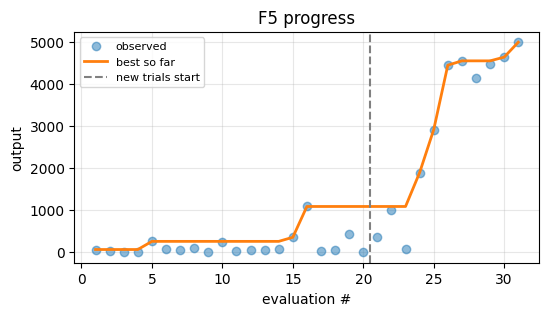

In [3]:
# =====================================================================
# RECOMMEND: fit the chosen surrogate on all data so far and print the next
# point to run. Re-run this cell any time; it always reflects the latest trials.
#
# Two things changed in week 4:
#   * SURROGATE selects the model. The Matern GP allows any interaction between
#     inputs, which is expensive when data is scarce; "additive" forbids
#     interactions and "quadratic" fits a polynomial trend with a GP on the
#     residual. Which one is right is an empirical question -- run the CHECK cell.
#   * PROPOSER selects HOW the point is chosen. "acquisition" is the classic
#     EI/UCB optimisation over the whole (or trust-region) box, and is justified
#     only when the surrogate can predict points it has not seen. "local" instead
#     scores a handful of small moves away from the current best, so the model
#     only has to RANK nearby options rather than locate a global optimum.
# =====================================================================
def _probe_point(X):
    """Serve an explicit probe before falling back to the model.

    Used when direct measurements contradict the surrogate. At the corner this
    function now occupies, the three readings along its one free input run
    4451.7, 4478.9, 4554.8 -- monotonically INCREASING -- while the global model
    predicts a peak below them and mis-predicts its own measured point there by
    126. A model whose local slope has the wrong sign does not get to choose the
    next point; the measurements do. This probe steps past the highest reading to
    find out whether the rise continues."""
    for probe in PROBE_QUEUE:
        p = np.clip(np.asarray(probe, dtype=float).ravel(), EPS, 1.0 - EPS)
        if np.min(np.linalg.norm(X - p, axis=1)) > 1e-3:
            return p, "explicit probe (measurements contradict the model)"
    return None, None


def _lengthscales(model):
    try:
        for p, v in model.kernel_.get_params().items():
            if p.endswith("length_scale") and not p.endswith("bounds"):
                v = np.atleast_1d(v).astype(float)
                if np.all(v < 1e4):
                    return v
    except Exception:
        pass
    return None


def _transform(y):
    if TRANSFORM == "log":
        return np.log(y), "log y"
    if TRANSFORM == "log10abs":
        return np.log10(np.abs(y)), "log10|y|"
    return y, "y"


def recommend(verbose=True, plot=True):
    X, y = load_all()
    y_fit, ylabel = _transform(y)

    model = fit_surrogate(
        X, y_fit, kind=SURROGATE, noise=NOISE,
        length_scale_bounds=LENGTHSCALE_BOUNDS, random_state=RANDOM_STATE,
    )
    # Step sizes come from a plain Matern fit even when another surrogate ranks
    # the candidates: a trend model's residual lengthscales describe what the
    # trend left over, not the scale on which the function actually varies.
    ref = model if SURROGATE == "matern" else fit_surrogate(
        X, y_fit, kind="matern", noise=NOISE,
        length_scale_bounds=LENGTHSCALE_BOUNDS, random_state=RANDOM_STATE,
    )
    ls = _lengthscales(ref)

    best_i = int(np.argmax(y_fit))
    best_x = X[best_i]
    y_best_fit = float(np.max(np.ravel(model.predict(X))))

    table = None
    if PROPOSER == "local" and PROBE_QUEUE and _probe_point(X)[0] is not None:
        x_next, how = _probe_point(X)

    elif PROPOSER == "local":
        x_next, table = propose_local(
            model, X, y_fit, lengthscales=ls, step_frac=STEP_FRAC,
            score=SCORE, xi=XI, beta=BETA, plausible_max=PLAUSIBLE_MAX,
            inert_threshold=INERT_THRESHOLD, min_step=MIN_STEP,
            eps=EPS, verbose=verbose,
        )
        how = f"local candidates ranked by {SCORE.upper()}"

    elif PROPOSER == "replicate":
        x_next = best_x.copy()
        for j in range(DIM):
            if ls is None or ls[j] > INERT_THRESHOLD:
                shift = -REPLICATE_SHIFT if x_next[j] > 0.5 else REPLICATE_SHIFT
                x_next[j] = float(np.clip(x_next[j] + shift, EPS, 1.0 - EPS))
        how = "near-replicate of the incumbent (inert axes only) to measure noise"

    else:
        bounds = (trust_region_bounds(best_x, TR_RADIUS, EPS, 1.0 - EPS)
                  if TRUST_REGION else (EPS, 1.0 - EPS))
        x_next, _ = propose_next_point(
            model, dim=DIM, acquisition=ACQUISITION, xi=XI, beta=BETA,
            y_best=y_best_fit, bounds=bounds, random_state=RANDOM_STATE,
        )
        how = (f"{ACQUISITION.upper()} "
               f"({'beta='+str(BETA) if ACQUISITION=='ucb' else 'xi='+str(XI)})"
               + (f"  [trust region r={TR_RADIUS}]" if TRUST_REGION else ""))

    x_next = np.clip(np.asarray(x_next, dtype=float).ravel(), EPS, 1.0 - EPS)

    mu, sd = model.predict(x_next.reshape(1, -1), return_std=True)
    mu, sd = float(np.ravel(mu)[0]), float(np.ravel(sd)[0])

    if verbose:
        print(f"=== FUNCTION {FUNC_ID} ===")
        print(f"observed points: {len(y)}  (initial {len(y)-n_new_trials()} + "
              f"new {n_new_trials()});  new-trial budget: {n_new_trials()}/{TRIAL_BUDGET}")
        print(f"surrogate: {SURROGATE}   target: {ylabel}   proposer: {PROPOSER}")
        print(f"best so far: y={y[int(np.argmax(y))]:.4g} at x=["
              + ", ".join(f"{v:.6f}" for v in X[int(np.argmax(y))]) + "]")
        print(f"rule: {how}")
        print("-" * 62)
        print(">>> NEXT POINT TO SUBMIT:")
        print("    [" + ", ".join(f"{v:.6f}" for v in x_next) + "]")
        if TRANSFORM == "log":
            print(f"    predicted: exp(mu)={np.exp(mu):.4g}  "
                  f"(log-space {mu:.3f} +/- {sd:.3f})")
        else:
            print(f"    predicted {ylabel}: {mu:.4g} +/- {sd:.4g}")
        print(f"    {'ABOVE' if mu > y_fit[best_i] else 'below'} the incumbent"
              f"   |   distance to it: {np.linalg.norm(x_next - best_x):.3f}")
        if ls is not None:
            print("    lengthscales (small = influential):",
                  np.round(ls, 3).tolist())

    if plot:
        _progress_plot(X, y)
    return x_next, model


def _progress_plot(X, y):
    n_init = len(y) - n_new_trials()
    running_best = np.maximum.accumulate(y)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(range(1, len(y)+1), y, "o", alpha=0.5, label="observed")
    ax.plot(range(1, len(y)+1), running_best, "-", lw=2, label="best so far")
    ax.axvline(n_init + 0.5, ls="--", c="gray", label="new trials start")
    ax.set_xlabel("evaluation #"); ax.set_ylabel("output"); ax.legend(fontsize=8)
    ax.set_title(f"F{FUNC_ID} progress"); ax.grid(alpha=0.3); plt.show()

x_next, model = recommend()


## 4 · Check: is this still the right model? *(optional, slow)*

Recomputes the leave-one-out score for three candidate models on this function's
current data, and marks which one is in use.

This takes a minute or two because it refits the model once per observation. You do
not need to run it every week — every few rounds is enough. If a different model
wins by a clear margin (roughly 0.1 or more), change `SURROGATE` in the settings
cell and note the change in `WEEKLY_LOG.md`.


In [4]:
# =====================================================================
# CHECK (optional, slow): which surrogate actually predicts this function best?
# =====================================================================
# Leave-one-out Q2: remove each observation, refit on the rest, predict the one
# removed. Q2 = 1 is perfect; Q2 = 0 is no better than always guessing the mean;
# Q2 < 0 is worse than that. This is the test of whether the surrogate has earned
# the right to pick a point somewhere nobody has measured -- in-sample fit does
# NOT answer that (every model here interpolates its own data almost perfectly).
#
# Re-run this every few rounds. The winner changes as data accumulates, and a
# challenger should only replace the incumbent on a clear margin (>= 0.1);
# with a few dozen points, smaller differences are noise.
X, y = load_all()
y_fit, _ = _transform(y)
for kind in ("matern", "additive", "quadratic"):
    try:
        q2 = loo_q2(X, y_fit, kind=kind, n_restarts_optimizer=2,
                    random_state=RANDOM_STATE)
        flag = "   <-- in use" if kind == SURROGATE else ""
        print(f"  {kind:<10}  LOO Q2 = {q2:+.3f}{flag}")
    except Exception as exc:
        print(f"  {kind:<10}  failed: {exc}")


  matern      LOO Q2 = +0.574


  additive    LOO Q2 = +0.607


  quadratic   LOO Q2 = +0.859   <-- in use


## 5 · Record the result, get the next point

After the output arrives, paste it into `NEW_Y` and run this cell. It appends the
point and its result to `new_trials.csv` — which is what makes the history survive
between sessions — then refits and prints the next recommendation straight away.

`NEW_X` defaults to the point this notebook last recommended. If you submitted
something different, edit it to match what you actually ran; the log has to record
reality, not intention.

Afterwards set `NEW_Y = None` again. Left filled in, the next run of this notebook
would append the same trial a second time and quietly corrupt the record.


In [5]:
# =====================================================================
# ADD A REALISED TRIAL: after you run the recommended point in the real
# experiment and get its output, record it here, then re-run to get the
# NEXT recommendation. (Appends to new_trials.csv, so it persists.)
# =====================================================================
# 1) paste the point you actually submitted (length must be DIM, values in [0,1])
NEW_X = list(x_next)          # defaults to the last recommendation; edit if you ran a different point
# 2) paste the output you observed for it
NEW_Y = None

def append_trial(new_x, new_y):
    new_x = np.asarray(new_x, dtype=float).ravel()
    assert new_x.shape[0] == DIM, f"NEW_X must have length {DIM}"
    assert (new_x >= -1e-9).all() and (new_x <= 1+1e-9).all(), "inputs must be in [0,1]"
    assert new_y is not None, "Set NEW_Y to the observed output before running."
    row = {f"x{j}": float(new_x[j]) for j in range(DIM)}
    row["y"] = float(new_y)
    df = pd.read_csv(LOG_CSV) if LOG_CSV.exists() else pd.DataFrame(columns=list(row))
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(LOG_CSV, index=False)
    print(f"Recorded trial #{len(df)}: x={np.round(new_x,4).tolist()} -> y={new_y}")
    print(f"Saved to {LOG_CSV.name}. Re-run the RECOMMEND cell for the next point.")

if NEW_Y is not None:
    append_trial(NEW_X, NEW_Y)
    x_next, gp = recommend()          # immediately show the next recommendation
else:
    print("Set NEW_Y to the observed output (and adjust NEW_X if needed), then run this cell.")

Set NEW_Y to the observed output (and adjust NEW_X if needed), then run this cell.
